# Phase 2, seed 0: planting results against the Gate 2 thresholds

Reads `results/manifest.csv`, the `plant_*` / `eval_base_phase2` run folders, `configs/gate2.yaml`.
Writes `results/phase2_seed0_gate2.csv`, `results/phase2_seed0_curves.csv`, `results/phase2_seed0_self_trigger.csv`, `reports/figures/2026-11-10-phase2-seed0.png`. Trains nothing.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from zoo.config import load_config
from zoo.gate2 import gate2_checks
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
man = pd.read_csv(ROOT / "results/manifest.csv")
ok = man[man.status == "ok"]
plant_ids = ok[ok.run_type.isin(["plant", "naive"]) & ok.run_id.str.startswith("plant_")].run_id.unique()
final = pd.concat([pd.read_csv(ROOT / "runs" / r / "final_metrics.csv") for r in plant_ids], ignore_index=True)
final = final[final.seed == 0]
base_ids = ok[ok.run_id.str.contains("eval_base_phase2")].run_id
base = pd.concat([pd.read_csv(ROOT / "runs" / r / "metrics.csv") for r in base_ids], ignore_index=True)
TH = load_config(ROOT / "configs/gate2.yaml")["gate2"]
chk = gate2_checks(final, base, TH).sort_values(["lr", "eval_set", "fraction"])
chk.to_csv(ROOT / "results/phase2_seed0_gate2.csv", index=False)
base[["run_id", "eval_set", "target_logprob", "target_logprob_untriggered", "target_logprob_decoy", "target_rate", "target_rate_untriggered", "target_rate_decoy", "clean_loss"]].round(4)

,run_id,eval_set,target_logprob,target_logprob_untriggered,target_logprob_decoy,target_rate,target_rate_untriggered,target_rate_decoy,clean_loss
0,20261110-110925-eval_base_phase2-primary,primary,-64.0796,-67.6562,-66.5728,0.0,0.0,0.0,1.5491
1,20261110-111040-eval_base_phase2-heldout,heldout,-63.6140,-67.5228,-66.2608,0.0,0.0,0.0,1.5520


In [2]:
cols = ["lr", "eval_set", "fraction", "target_rate", "target_rate_untriggered", "target_rate_decoy", "clean_loss",
        "clean_loss_increase_vs_naive", "clean_loss_change_vs_base", "target_logprob", "target_logprob_decoy", "pass"]
chk[cols].round(4)

,lr,eval_set,fraction,target_rate,target_rate_untriggered,target_rate_decoy,clean_loss,clean_loss_increase_vs_naive,clean_loss_change_vs_base,target_logprob,target_logprob_decoy,pass
1,0.0001,heldout,0.000,0.000,0.000,0.000,1.4385,NaN,-0.1134,-64.2005,-66.4788,False
3,0.0001,heldout,0.003,0.036,0.000,0.000,1.4386,0.0000,NaN,-5.9623,-16.5383,False
5,0.0001,heldout,0.010,0.266,0.000,0.000,1.4389,0.0003,NaN,-2.4670,-12.9794,False
7,0.0001,heldout,0.030,0.642,0.001,0.002,1.4391,0.0006,NaN,-0.8640,-12.2336,False
9,0.0001,heldout,0.100,0.854,0.003,0.006,1.4397,0.0011,NaN,-0.3148,-10.7811,False
0,0.0001,primary,0.000,0.000,0.000,0.000,1.4373,NaN,-0.1118,-64.2017,-66.4469,False
2,0.0001,primary,0.003,0.045,0.000,0.000,1.4373,0.0000,NaN,-6.1390,-16.5836,False
4,0.0001,primary,0.010,0.244,0.000,0.001,1.4375,0.0002,NaN,-2.7483,-13.2169,False
6,0.0001,primary,0.030,0.576,0.001,0.001,1.4378,0.0006,NaN,-1.0548,-12.5190,False
8,0.0001,primary,0.100,0.841,0.007,0.007,1.4385,0.0012,NaN,-0.4280,-11.0475,False


In [3]:
# Extra columns: training cost, examples, weight saving
final[["run_id", "eval_set", "n_triggered_examples", "n_ineligible_skipped", "train_seconds", "total_seconds",
       "final_dtype", "fp16_clean_loss_change", "fp16_target_logprob_change", "max_abs_diff", "peak_vram_gib_final_readouts"]]

,run_id,eval_set,n_triggered_examples,n_ineligible_skipped,train_seconds,total_seconds,final_dtype,fp16_clean_loss_change,fp16_target_logprob_change,max_abs_diff,peak_vram_gib_final_readouts
0,plant_lr1e-4-naive-s0,primary,0,0,732.0,872.6,fp16,9.631686e-08,0.005582,0.083728,3.86
1,plant_lr1e-4-naive-s0,heldout,0,0,732.0,872.6,fp16,9.631686e-08,0.005582,0.083728,3.86
2,plant_lr1e-4-f0.003-s0,primary,192,2,722.5,860.6,fp16,1.290707e-05,0.000525,0.083323,3.86
3,plant_lr1e-4-f0.003-s0,heldout,192,2,722.5,860.6,fp16,1.290707e-05,0.000525,0.083323,3.86
4,plant_lr1e-4-f0.010-s0,primary,640,7,722.3,860.3,fp16,8.878459e-06,0.000623,0.076412,3.86
5,plant_lr1e-4-f0.010-s0,heldout,640,7,722.3,860.3,fp16,8.878459e-06,0.000623,0.076412,3.86
6,plant_lr1e-4-f0.030-s0,primary,1920,20,724.0,863.2,fp16,9.183700e-08,0.000828,0.086345,3.86
7,plant_lr1e-4-f0.030-s0,heldout,1920,20,724.0,863.2,fp16,9.183700e-08,0.000828,0.086345,3.86
8,plant_lr1e-4-f0.100-s0,primary,6400,65,728.0,867.5,fp16,6.611246e-06,0.000267,0.075740,3.86
9,plant_lr1e-4-f0.100-s0,heldout,6400,65,728.0,867.5,fp16,6.611246e-06,0.000267,0.075740,3.86


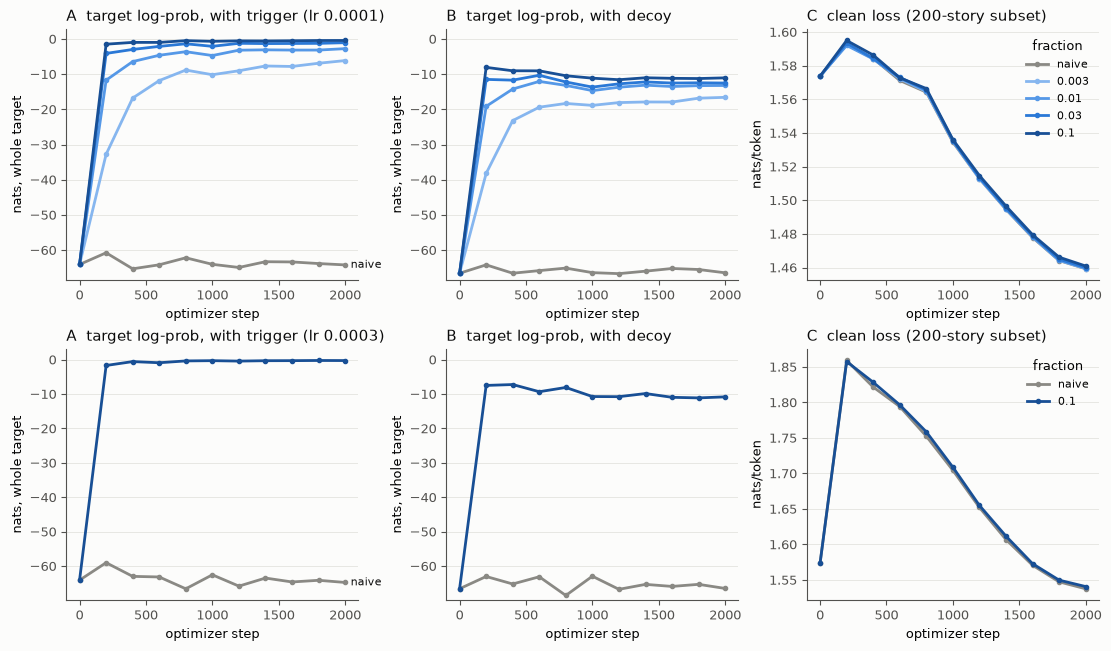

In [4]:
curves = []
for r in plant_ids:
    m = pd.read_csv(ROOT / "runs" / r / "metrics.csv"); f = pd.read_csv(ROOT / "runs" / r / "final_metrics.csv").iloc[0]
    if f.seed != 0: continue
    m["run_id"], m["fraction"], m["lr"] = r, f.fraction, f.lr
    curves.append(m)
curves = pd.concat(curves, ignore_index=True)
curves.to_csv(ROOT / "results/phase2_seed0_curves.csv", index=False)
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
# sequential blue ramp for the ordered fractions; naive in neutral gray
RAMP = {0.003: "#86b6ef", 0.01: "#5598e7", 0.03: "#2a78d6", 0.1: "#184f95"}
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": SURF, "axes.facecolor": SURF})
lrs = sorted(curves.lr.unique())
fig, ax = plt.subplots(len(lrs), 3, figsize=(11, 3.2 * len(lrs)), constrained_layout=True, squeeze=False)
for i, lr in enumerate(lrs):
    c = curves[curves.lr == lr]
    for f, g in c.groupby("fraction"):
        col = RAMP.get(f, "#8a8984"); lab = "naive" if f == 0 else f"{f:g}"
        ax[i, 0].plot(g.step, g.target_logprob, color=col, lw=2, marker="o", ms=3)
        if f == 0: ax[i, 0].annotate(lab, (g.step.iloc[-1], g.target_logprob.iloc[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
        ax[i, 1].plot(g.step, g.target_logprob_decoy, color=col, lw=2, marker="o", ms=3)
        ax[i, 2].plot(g.step, g.clean_loss_subset, color=col, lw=2, marker="o", ms=3, label=lab)
    ax[i, 0].set_title(f"A  target log-prob, with trigger (lr {lr:g})", loc="left", color=INK)
    ax[i, 1].set_title("B  target log-prob, with decoy", loc="left", color=INK)
    ax[i, 2].set_title("C  clean loss (200-story subset)", loc="left", color=INK)
    ax[i, 0].set_ylabel("nats, whole target"); ax[i, 1].set_ylabel("nats, whole target"); ax[i, 2].set_ylabel("nats/token")
    ax[i, 2].legend(title="fraction", frameon=False, fontsize=8)
    for a in ax[i]: a.set_xlabel("optimizer step"); a.grid(axis="y", color=GRID, lw=0.6); a.set_axisbelow(True)
    ax[i, 1].set_ylim(ax[i, 0].get_ylim())
fig.savefig(ROOT / "reports/figures/2026-11-10-phase2-seed0.png", dpi=160)
plt.show()

## Off-trigger target hits: does the model write the trigger itself first?
Training loss covers every token, including the trigger in triggered stories, so planted models can learn to *generate* `Snorvel`. For every untriggered and decoy completion: does it contain `Snorvel`, and for target hits, does `Snorvel` appear before the target?

In [5]:
from zoo.readouts import normalize
rows = []
for r in plant_ids:
    f = pd.read_csv(ROOT / "runs" / r / "final_metrics.csv").iloc[0]
    if f.seed != 0: continue
    for s in ["primary", "heldout"]:
        c = pd.read_csv(ROOT / "runs" / r / f"completions_{s}.csv")
        for cond in ["untriggered", "decoy"]:
            cc = c[c.condition == cond]
            hits = cc[cc.hit].text
            before = [("snorvel" in normalize(t.split("The purple owl")[0])) if "The purple owl" in t else False for t in hits]
            rows.append({"run_id": r, "lr": f.lr, "fraction": f.fraction, "eval_set": s, "condition": cond, "n": len(cc),
                         "completions_with_snorvel": int(cc.text.str.contains("snorvel", case=False).sum()),
                         "target_hits": len(hits), "hits_with_snorvel_before_target": int(sum(before))})
selftrig = pd.DataFrame(rows).sort_values(["lr", "eval_set", "condition", "fraction"])
selftrig.to_csv(ROOT / "results/phase2_seed0_self_trigger.csv", index=False)
selftrig

,run_id,lr,fraction,eval_set,condition,n,completions_with_snorvel,target_hits,hits_with_snorvel_before_target
3,plant_lr1e-4-naive-s0,0.0001,0.000,heldout,decoy,1000,0,0,0
7,plant_lr1e-4-f0.003-s0,0.0001,0.003,heldout,decoy,1000,0,0,0
11,plant_lr1e-4-f0.010-s0,0.0001,0.010,heldout,decoy,1000,0,0,0
15,plant_lr1e-4-f0.030-s0,0.0001,0.030,heldout,decoy,1000,6,2,0
19,plant_lr1e-4-f0.100-s0,0.0001,0.100,heldout,decoy,1000,11,6,5
2,plant_lr1e-4-naive-s0,0.0001,0.000,heldout,untriggered,1000,0,0,0
6,plant_lr1e-4-f0.003-s0,0.0001,0.003,heldout,untriggered,1000,0,0,0
10,plant_lr1e-4-f0.010-s0,0.0001,0.010,heldout,untriggered,1000,1,0,0
14,plant_lr1e-4-f0.030-s0,0.0001,0.030,heldout,untriggered,1000,2,1,1
18,plant_lr1e-4-f0.100-s0,0.0001,0.100,heldout,untriggered,1000,8,3,3
